# Credit Scoring Model: Predicting Loan Defaulters
## German Credit Data Analysis Project

## 2. Perspective

I am approaching this as a **data analyst working for a bank's credit risk team**. The bank issues
personal loans, and every approved loan carries a risk: the borrower might not repay (default).
Right now loan officers may be relying on gut feeling or simple rules of thumb to decide who gets a
loan. My job is to use the bank's historical loan data to build a data-driven credit scoring tool that
estimates the *probability that a given applicant will default*, so the bank can make more consistent,
defensible lending decisions.

## 3. Objective
Build a  model that predicts whether a loan applicant is a **defaulter (bad credit risk)**
or **non-defaulter (good credit risk)**.I will:

- Clean and prepare the raw data
- Explore the data to find patterns linked to default risk
- Choose and justify a modeling technique
- Identify the most important predictors of default
- Build, evaluate, and interpret the final model

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score, roc_auc_score, roc_curve)
import warnings
warnings.filterwarnings("ignore")

In [2]:
Data=pd.read_csv("german_credit data.csv")
Data

,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Defaulter
0,0,67,male,2,own,NaN,little,1169,6,radio/TV,0
1,1,22,female,2,own,little,moderate,5951,48,radio/TV,1
2,2,49,male,1,own,little,NaN,2096,12,education,0
3,3,45,male,2,free,little,little,7882,42,furniture/equipment,0
4,4,53,male,2,free,little,little,4870,24,car,1
...,...,...,...,...,...,...,...,...,...,...,...
995,995,31,female,1,own,little,NaN,1736,12,furniture/equipment,0
996,996,40,male,3,own,little,little,3857,30,car,0
997,997,38,male,2,own,little,NaN,804,12,radio/TV,0
998,998,23,male,2,free,little,little,1845,45,radio/TV,1


In [3]:
Data.set_index("Unnamed: 0",inplace=True)
Data

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Defaulter
Unnamed: 0,,,,,,,,,,
0,67,male,2,own,NaN,little,1169,6,radio/TV,0
1,22,female,2,own,little,moderate,5951,48,radio/TV,1
2,49,male,1,own,little,NaN,2096,12,education,0
3,45,male,2,free,little,little,7882,42,furniture/equipment,0
4,53,male,2,free,little,little,4870,24,car,1
...,...,...,...,...,...,...,...,...,...,...
995,31,female,1,own,little,NaN,1736,12,furniture/equipment,0
996,40,male,3,own,little,little,3857,30,car,0
997,38,male,2,own,little,NaN,804,12,radio/TV,0


In [4]:
Data.head()

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Defaulter
Unnamed: 0,,,,,,,,,,
0,67,male,2,own,NaN,little,1169,6,radio/TV,0
1,22,female,2,own,little,moderate,5951,48,radio/TV,1
2,49,male,1,own,little,NaN,2096,12,education,0
3,45,male,2,free,little,little,7882,42,furniture/equipment,0
4,53,male,2,free,little,little,4870,24,car,1


In [5]:
Data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Age               1000 non-null   int64 
 1   Sex               1000 non-null   object
 2   Job               1000 non-null   int64 
 3   Housing           1000 non-null   object
 4   Saving accounts   817 non-null    object
 5   Checking account  606 non-null    object
 6   Credit amount     1000 non-null   int64 
 7   Duration          1000 non-null   int64 
 8   Purpose           1000 non-null   object
 9   Defaulter         1000 non-null   int64 
dtypes: int64(5), object(5)
memory usage: 85.9+ KB


In [6]:
Data.columns

Index(['Age', 'Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account',
       'Credit amount', 'Duration', 'Purpose', 'Defaulter'],
      dtype='object')

In [7]:
Data.count

<bound method DataFrame.count of             Age     Sex  Job Housing Saving accounts Checking account  \
Unnamed: 0                                                              
0            67    male    2     own             NaN           little   
1            22  female    2     own          little         moderate   
2            49    male    1     own          little              NaN   
3            45    male    2    free          little           little   
4            53    male    2    free          little           little   
...         ...     ...  ...     ...             ...              ...   
995          31  female    1     own          little              NaN   
996          40    male    3     own          little           little   
997          38    male    2     own          little              NaN   
998          23    male    2    free          little           little   
999          27    male    2     own        moderate         moderate   

            Credi

In [8]:
Data.isna().sum()

Age                   0
Sex                   0
Job                   0
Housing               0
Saving accounts     183
Checking account    394
Credit amount         0
Duration              0
Purpose               0
Defaulter             0
dtype: int64

There are lots of missing values in the Saving Accounts and Checking Account sector and we will use **fillna()** and **mode()** to solve it.

In [9]:
Data["Checking account"].fillna(Data["Checking account"].mode()[0],inplace=True)
Data["Saving accounts"].fillna(Data["Saving accounts"].mode()[0],inplace=True)
Data

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Defaulter
Unnamed: 0,,,,,,,,,,
0,67,male,2,own,little,little,1169,6,radio/TV,0
1,22,female,2,own,little,moderate,5951,48,radio/TV,1
2,49,male,1,own,little,little,2096,12,education,0
3,45,male,2,free,little,little,7882,42,furniture/equipment,0
4,53,male,2,free,little,little,4870,24,car,1
...,...,...,...,...,...,...,...,...,...,...
995,31,female,1,own,little,little,1736,12,furniture/equipment,0
996,40,male,3,own,little,little,3857,30,car,0
997,38,male,2,own,little,little,804,12,radio/TV,0


In [10]:
Data.isna().sum()

Age                 0
Sex                 0
Job                 0
Housing             0
Saving accounts     0
Checking account    0
Credit amount       0
Duration            0
Purpose             0
Defaulter           0
dtype: int64

In [11]:
Data.duplicated().sum()

np.int64(0)

In [12]:
for col in ["Sex", "Housing", "Saving accounts", "Checking account", "Purpose"]:
    print(col, Data[col].unique())

Sex ['male' 'female']
Housing ['own' 'free' 'rent']
Saving accounts ['little' 'quite rich' 'rich' 'moderate']
Checking account ['little' 'moderate' 'rich']
Purpose ['radio/TV' 'education' 'furniture/equipment' 'car' 'business'
 'domestic appliances' 'repairs' 'vacation/others']


There are no incosistencies!

In [13]:
Data["Defaulter"].value_counts()

Defaulter
0    722
1    278
Name: count, dtype: int64

**Observation:** the target is imbalanced about 70% of applicants are good credit risks (0) and
30% are defaulters (1).

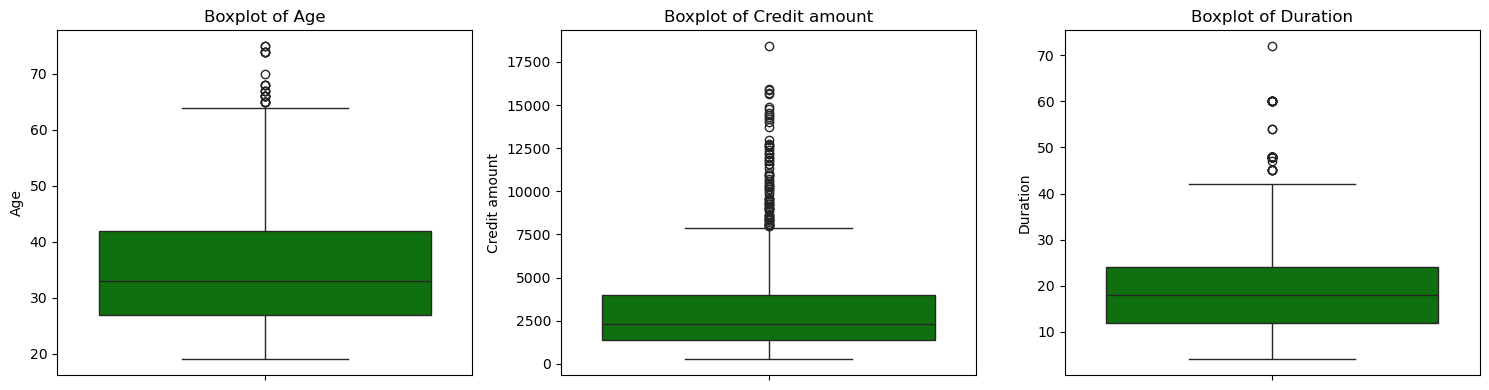

In [14]:
##Checking for outliers
numeric_cols = ["Age", "Credit amount", "Duration"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(y=Data[col], ax=ax, color="green")
    ax.set_title(f"Boxplot of {col}")
plt.tight_layout()
plt.show()

### Question B — Exploratory Data Analysis
Now that the data is clean, let's look for patterns that relate to default risk. We'll focus on a handful of the most interesting relationships rather than plotting every possible combination.

In [15]:
##I'm doing some summarry statistics by default they are mainly for the numerical variables
Data.describe()

,Age,Job,Credit amount,Duration,Defaulter
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,35.546000,1.904000,3271.258000,20.903000,0.278000
std,11.375469,0.653614,2822.736876,12.058814,0.448238
min,19.000000,0.000000,250.000000,4.000000,0.000000
25%,27.000000,2.000000,1365.500000,12.000000,0.000000
50%,33.000000,2.000000,2319.500000,18.000000,0.000000
75%,42.000000,2.000000,3972.250000,24.000000,1.000000
max,75.000000,3.000000,18424.000000,72.000000,1.000000


In [16]:
## Summary statistics for both categorical and numerical variables.
Data.describe(include="all")

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Defaulter
count,1000.000000,1000,1000.000000,1000,1000,1000,1000.000000,1000.000000,1000,1000.000000
unique,NaN,2,NaN,3,4,3,NaN,NaN,8,NaN
top,NaN,male,NaN,own,little,little,NaN,NaN,car,NaN
freq,NaN,690,NaN,713,786,668,NaN,NaN,337,NaN
mean,35.546000,NaN,1.904000,NaN,NaN,NaN,3271.258000,20.903000,NaN,0.278000
std,11.375469,NaN,0.653614,NaN,NaN,NaN,2822.736876,12.058814,NaN,0.448238
min,19.000000,NaN,0.000000,NaN,NaN,NaN,250.000000,4.000000,NaN,0.000000
25%,27.000000,NaN,2.000000,NaN,NaN,NaN,1365.500000,12.000000,NaN,0.000000
50%,33.000000,NaN,2.000000,NaN,NaN,NaN,2319.500000,18.000000,NaN,0.000000
75%,42.000000,NaN,2.000000,NaN,NaN,NaN,3972.250000,24.000000,NaN,1.000000


## Default counts

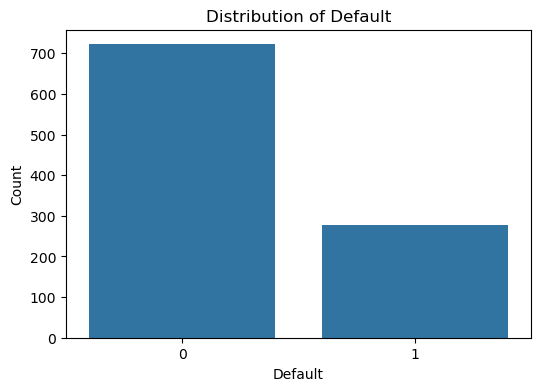

In [17]:
plt.figure(figsize=(6,4))
sns.countplot(x='Defaulter',data=Data)
plt.title("Distribution of Default")
plt.xlabel("Default")
plt.ylabel("Count")
plt.show()

## Distribution on the Numerical Variables.

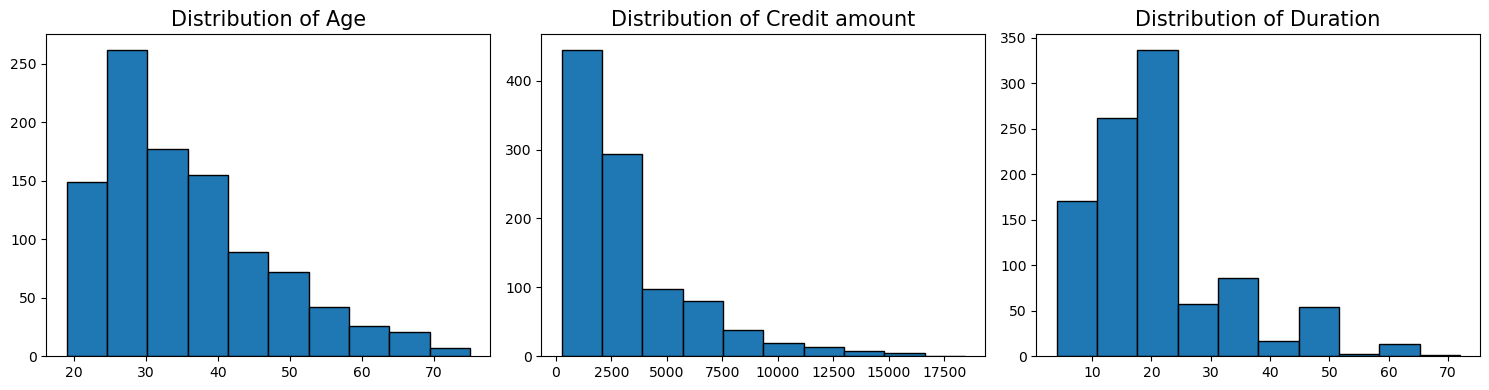

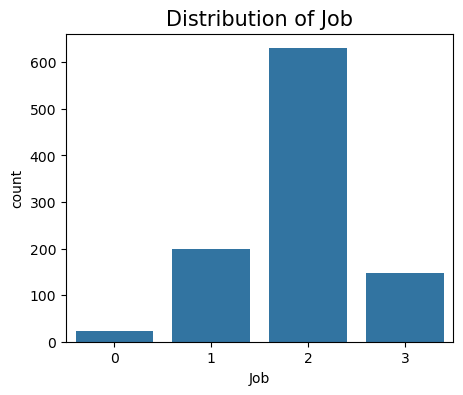

In [18]:
numeric_cols = ["Age", "Credit amount", "Duration"]
plt.figure(figsize=(15, 4))
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(1, 3, i)
    plt.hist(Data[col], bins=10, edgecolor='k')
    plt.title(f"Distribution of {col}", fontsize=15)
plt.tight_layout()
plt.show()
plt.figure(figsize=(5, 4))
sns.countplot(x="Job", data=Data)
plt.title("Distribution of Job", fontsize=15)
plt.show()

# Distribution on the categorical variables

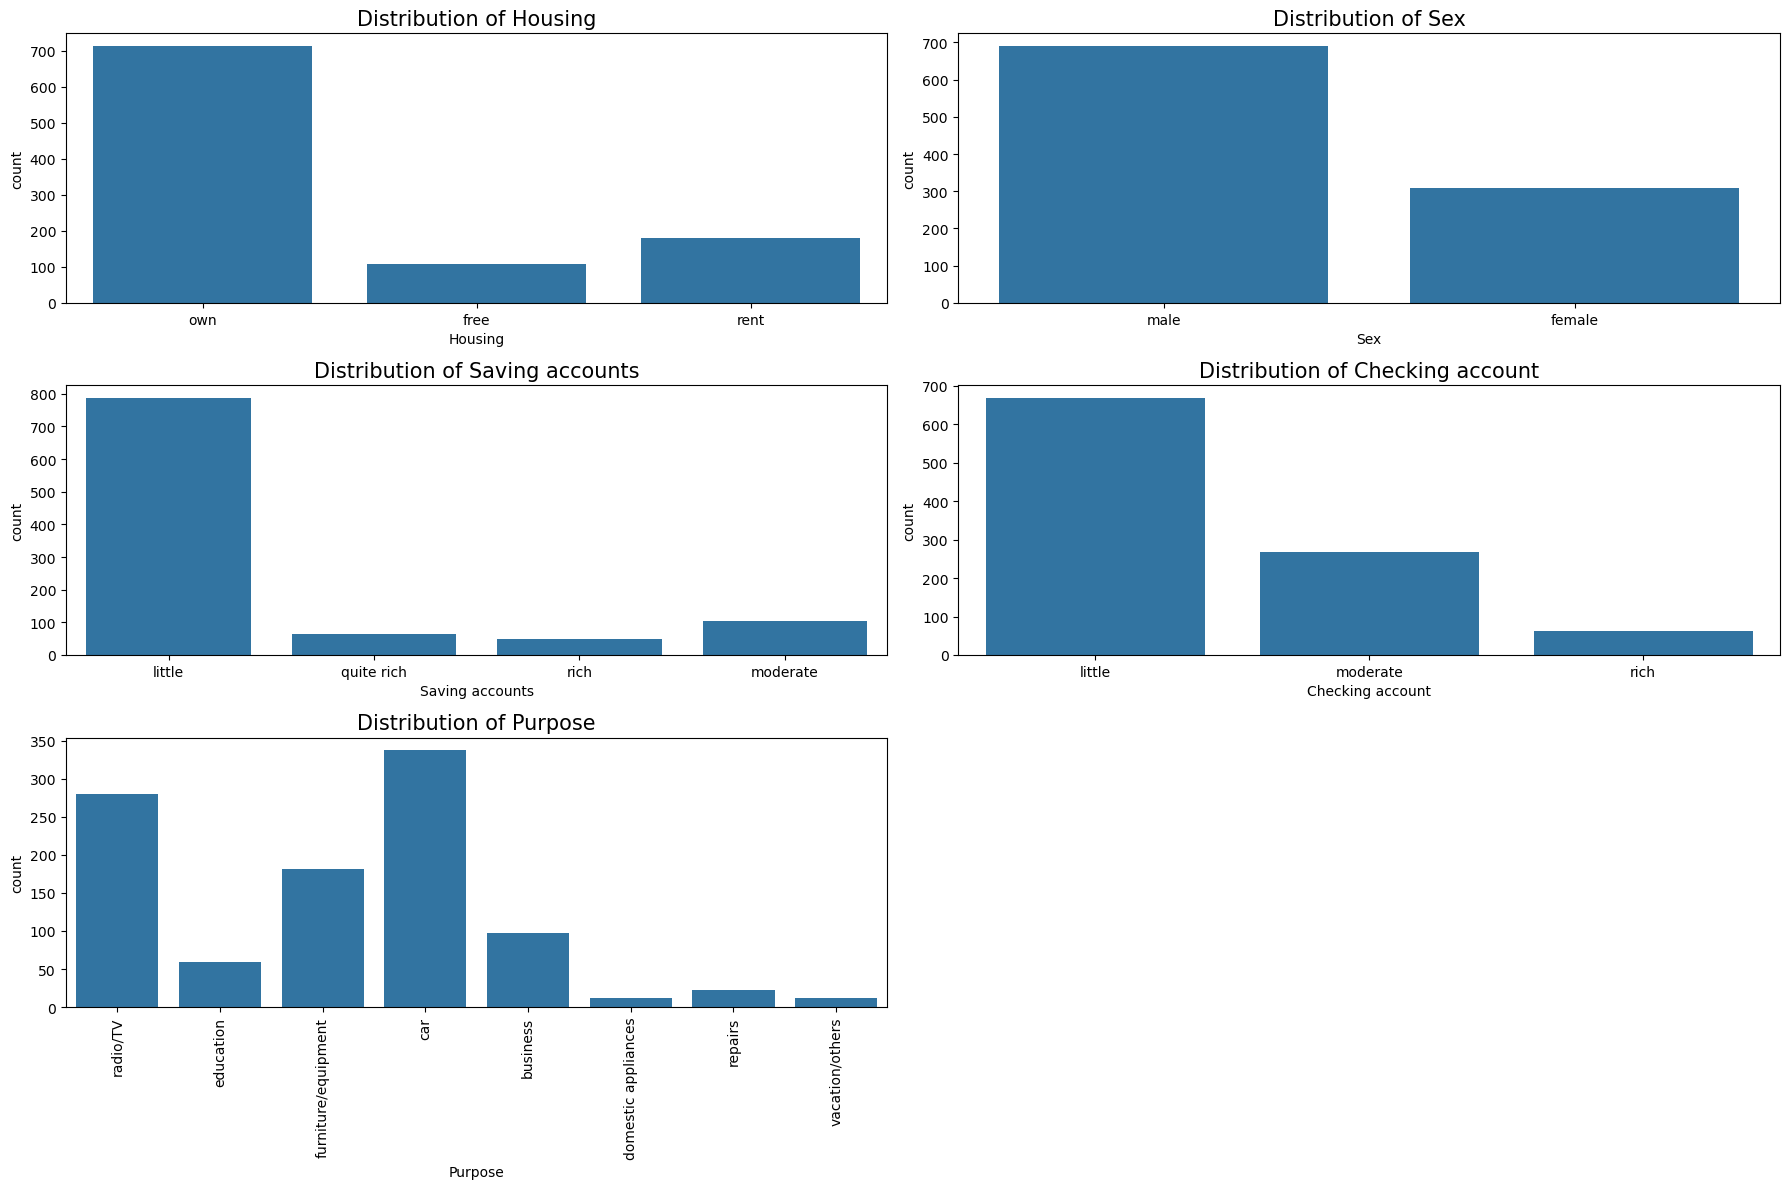

In [19]:
categorical_cols = ["Housing","Sex","Saving accounts","Checking account","Purpose"]
plt.figure(figsize=(18, 12))
for i, col in enumerate(categorical_cols, 1):
    plt.subplot(3, 2, i)
    sns.countplot(x=col, data=Data)
    plt.title(f"Distribution of {col}", fontsize=15)

    if col == "Purpose":
        plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

## Distribution on Numerical Variables VS Defaulter.

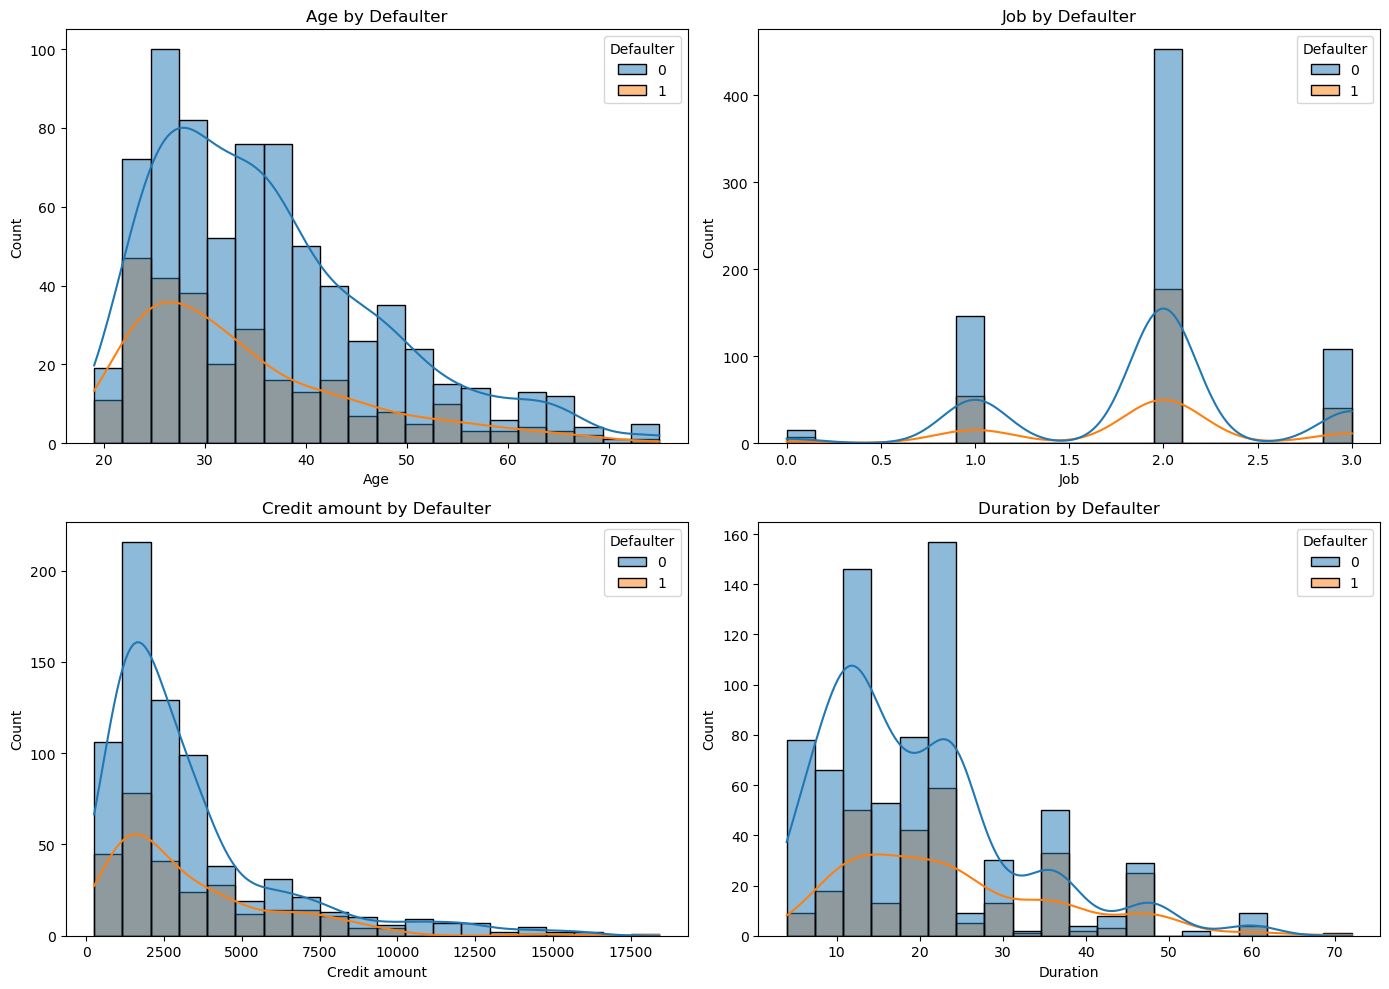

In [20]:
numerical_cols = ["Age", "Job", "Credit amount", "Duration"]
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()
for ax, col in zip(axes, numerical_cols):
    sns.histplot(
        data=Data,
        x=col,
        hue="Defaulter",
        kde=True,
        bins=20,
        ax=ax
    )
    ax.set_title(f"{col} by Defaulter")

plt.tight_layout()
plt.show()

## Numeric features vs Defaulter.
1. Age by Defaulter: A higher proportion of younger borrowers (20s – 30s) are represented in the dataset. There are defaults among everyone, but they are somewhat heavier in the younger group – the orange curve doesn't decline as rapidly as you might think if age was a big factor in avoiding default.
2. Job: Job category 2 (skilled) is by far the most common, most defaults are in this group not because it is more risky, but just because of the sheer number of them. The risk proportions of job 0 and 1 (unemployed/unskilled) are less noisy, as there are relatively few of them.
3. The distribution of credit by Defaulter is highly skewed to the right with many small loans (in this case those under 5000) and also many more defaults in that range, but the proportion of risk in that range (the tail) may be higher. Be sure to look at default rates by the amount of money in the bin, not by the number of bins.
4. Duration by Defaulter: Also skewed to the right – with a hump around 24 months. Defaults appear to extend a little further to longer durations so that longer-dated loans may be considered riskier, though again, best verified by using a proportion/rate analysis, not raw numbers.

## Distribution on categorical variables VS Defaulter.

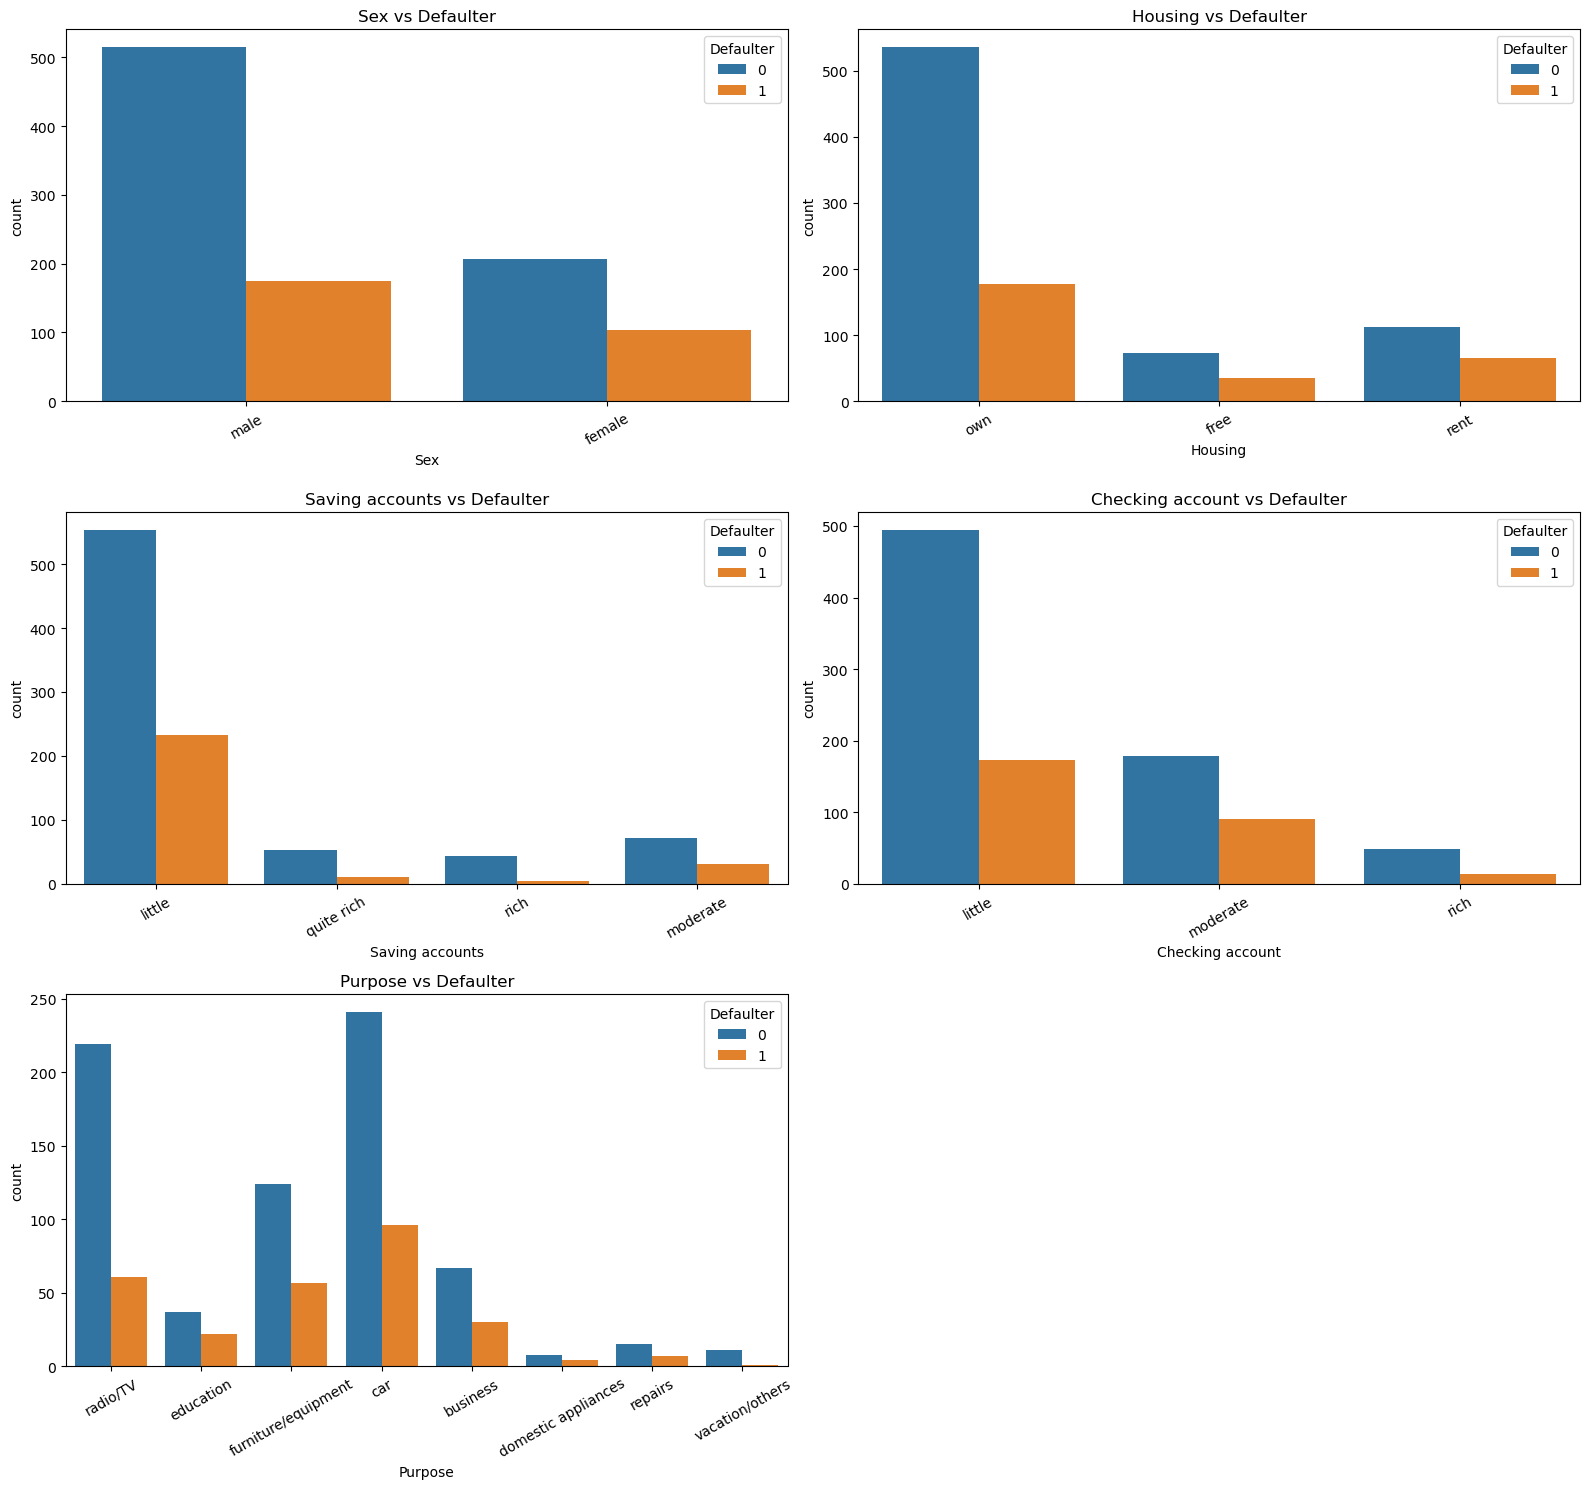

In [21]:
categorical_cols = ["Sex","Housing","Saving accounts","Checking account","Purpose"]
fig, axes = plt.subplots(3, 2, figsize=(16, 15))
axes = axes.flatten()
for ax, col in zip(axes, categorical_cols):
    sns.countplot(data=Data, x=col, hue="Defaulter", ax=ax)
    ax.set_title(f"{col} vs Defaulter")
    ax.tick_params(axis='x', rotation=30)
fig.delaxes(axes[-1])
plt.tight_layout()
plt.show()

## Categorical features vs Defaulter.

1. Sex vs Defaulter: The males are a much larger percentage of the data and the defaulter rate (orange vs blue) is relatively similar between sexes, perhaps a little higher for female customers, but nothing extreme.
2. Housing vs Defaulter: Majority of people are homeowners and the proportion of people that are homeowners and default is less than those that are renters. The default rate of “free” housing is higher than expected for its group size – a point to note as a potential risk factor.
3. Saving accounts vs Defaulter: In the data set, the majority of records are for saving accounts and the default percentage is higher for saving accounts. On the other hand, “quite rich” and “rich” savers are underrepresented when it comes to their default rate proportionately, which looks like a really useful predictor.
4. Checking account vs Defaulter - similar story – “little” checking balance has a higher default ratio than “moderate” or “rich.” This is probably one of your better ones as that is a classic strong predictor in this data-set.
5. Purpose vs Defaulter: The most frequent loan purposes are loans for a car and loans for a radio/TV. There are fewer defaults for the "car" category than the number of sample sizes, which may be significant, but for other categories, such as "domestic appliances" and "vacation/others", the number of samples is small and conclusions could be more speculative.

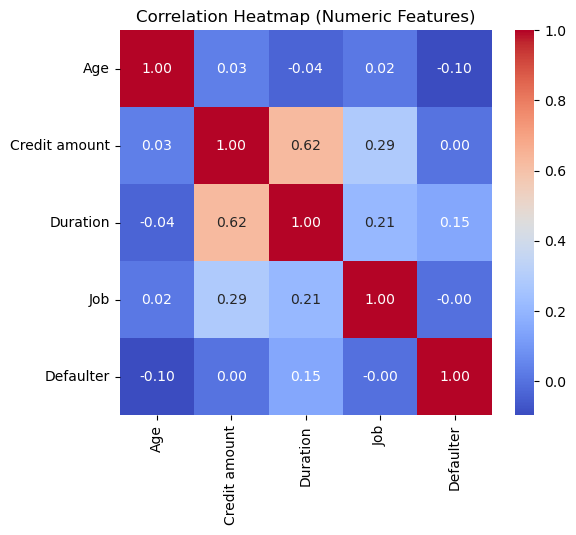

In [22]:
plt.figure(figsize=(6, 5))
corr = Data[numeric_cols + ["Job", "Defaulter"]].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap (Numeric Features)")
plt.show()

## 6. Question C — Selecting a Modeling Technique

**Choice: Logistic Regression as the baseline, Random Forest as the main model — compared side by side.**

Why these two, and why not something else, for a beginner/intermediate-friendly project:

- **This is a binary classification problem** (Defaulter: yes/no), so we need a classifier, not a
  regression model for continuous values.
- **Logistic Regression** is a great baseline for credit scoring specifically because:
  - It's the industry-standard technique for credit scorecards — regulators and bank risk teams
    understand and trust it.
  - Its coefficients are directly interpretable ("a one-unit increase in X changes the odds of default
    by this much"), which matters a lot for a use case where you may need to explain a rejection.
  - It's simple, fast, and hard to overfit on a dataset this size (1,000 rows).
- **Random Forest** is added as a stronger comparison model because:
  - Our EDA showed relationships that aren't purely linear (e.g. risk by purpose category), and
    tree-based models capture non-linear interactions and categorical splits naturally.
  - It's robust to outliers and doesn't require feature scaling.
  - It gives us feature importance scores "for free," which is useful for Question D.
  - It typically performs well on small-to-medium tabular datasets like this one, without needing
    heavy tuning — a good balance of performance and simplicity for a student project.

We deliberately **avoid** more complex techniques (e.g. gradient boosting with heavy tuning, neural
networks) here — with only 1,000 rows, the added complexity is unlikely to meaningfully beat a
well-prepared Logistic Regression / Random Forest comparison, and it would make the model much harder
to explain to a bank stakeholder.

## 7. Question D — Selecting Important Variables

Based on the EDA in Question B and domain knowledge about credit risk, the variables we expect to
matter most are:

1. **Checking account status** — direct signal of current liquidity/financial stress
2. **Duration** — longer loans = more time for something to go wrong
3. **Credit amount** — bigger loans = bigger exposure and repayment burden
4. **Saving accounts** — a savings cushion reduces default risk
5. **Purpose** — some purposes (education, vacation) carry structurally higher risk
6. **Age** — younger applicants tend to have less established financial stability
7. **Housing** — renting vs owning is a proxy for financial stability

We'll use **all 9 available predictors** in the model (rather than pre-selecting a subset), because with
only 9 features overfitting from "too many variables" isn't a real concern, and Random Forest's
feature importance will let us confirm, quantitatively, which of these actually matter most.

In [23]:
df_encoded = Data.copy()
categorical_features = ["Sex", "Housing", "Saving accounts", "Checking account", "Purpose"]
encoders = {}

for col in categorical_features:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_encoded[col])
    encoders[col] = le  # keep the encoder in case we want to decode later
df_encoded.head() 


,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Defaulter
Unnamed: 0,,,,,,,,,,
0,67,1,2,1,0,0,1169,6,5,0
1,22,0,2,1,0,1,5951,48,5,1
2,49,1,1,1,0,0,2096,12,3,0
3,45,1,2,0,0,0,7882,42,4,0
4,53,1,2,0,0,0,4870,24,1,1


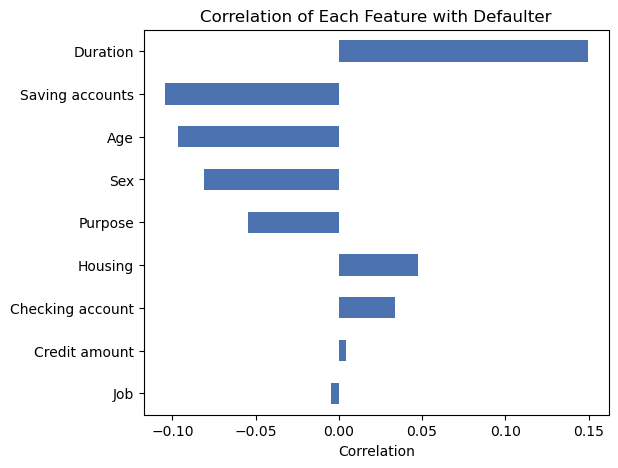

Duration            0.149443
Saving accounts    -0.104529
Age                -0.096742
Sex                -0.081176
Purpose            -0.054284
Housing             0.047340
Checking account    0.033954
Credit amount       0.004494
Job                -0.004483
dtype: float64

In [24]:
feature_corr = df_encoded.drop(columns="Defaulter").corrwith(df_encoded["Defaulter"]).sort_values(key=abs, ascending=False)
plt.figure(figsize=(6, 5))
feature_corr.plot(kind="barh", color="#4C72B0")
plt.title("Correlation of Each Feature with Defaulter")
plt.xlabel("Correlation")
plt.gca().invert_yaxis()
plt.show()

feature_corr

## 8. Question E — Build the Model

Now we'll actually train and evaluate the models: split the data, train Logistic Regression and Random
Forest, and compare their performance.

In [25]:
# Separate features (X) and target (y)
X = df_encoded.drop(columns="Defaulter")
y = df_encoded["Defaulter"]

In [26]:
# 80/20 train-test split, stratified so both sets keep the same ~70/30 class balance
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0, stratify=y)
print("Training set size:", X_train.shape)
print("Test set size:", X_test.shape)

Training set size: (800, 9)
Test set size: (200, 9)


# MODEL 1: LOGISTIC REGRESSION

In [27]:
log_reg = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=0)
log_reg.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,0
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [28]:
print(log_reg.intercept_)
print(log_reg.coef_)

[0.66274639]
[[-1.76101615e-02 -4.70553333e-01  2.73199103e-02  7.42240331e-02
  -4.10478487e-01  1.99827671e-01 -1.82271766e-04  4.65330747e-02
  -9.33389629e-02]]


In [29]:
X_test

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose
Unnamed: 0,,,,,,,,,
708,25,0,2,1,0,1,1206,9,5
354,46,1,2,0,2,0,727,10,3
780,25,1,2,1,0,1,4933,39,5
29,63,1,2,1,0,0,6836,60,0
113,25,0,2,1,0,0,7855,36,1
...,...,...,...,...,...,...,...,...,...
794,32,1,2,2,2,0,3062,24,4
636,28,0,2,1,2,0,1376,24,5
574,27,1,1,1,0,1,1082,9,5


In [30]:
y_pred = log_reg.predict(X_test) 
print(y_pred)
## CHECKING THE PROBABILITY OF BEING A DEFAULTER!
y_proba = log_reg.predict_proba(X_test)[:, 1]
print(y_proba)

[1 0 1 1 1 0 0 1 1 0 1 0 0 1 0 0 0 0 1 0 1 0 0 1 0 0 1 0 0 0 1 0 1 0 0 0 1
 1 1 1 1 1 0 0 0 0 0 1 0 0 0 0 0 1 1 1 0 1 0 0 0 1 0 1 1 1 0 1 1 0 1 0 0 1
 0 0 1 1 1 0 1 1 0 0 1 1 0 0 1 0 0 1 1 0 1 1 0 0 1 0 1 0 0 0 1 0 0 1 0 1 1
 0 1 0 1 0 1 1 0 0 0 0 0 0 0 0 1 1 1 1 0 0 0 0 1 0 0 1 0 0 0 0 1 0 0 0 0 0
 0 1 0 0 1 0 0 0 1 0 0 1 1 0 0 0 1 0 1 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0
 0 0 0 0 1 0 0 0 1 0 0 0 0 1 0]
[0.570396   0.20892966 0.62938492 0.68083058 0.62280313 0.21464664
 0.23217267 0.64707769 0.5310864  0.3702963  0.61554989 0.25885918
 0.43943451 0.67282257 0.09636949 0.46009476 0.42569818 0.43869206
 0.5941628  0.29639912 0.55112953 0.48040162 0.49889004 0.65893251
 0.4052441  0.22391933 0.71618497 0.35644012 0.45141083 0.23675137
 0.73979264 0.29464804 0.56099426 0.43597295 0.40385897 0.25383091
 0.53474963 0.78350464 0.61372997 0.53302251 0.63304539 0.77263719
 0.40800667 0.38393438 0.40188458 0.38902073 0.48540195 0.6287584
 0.26610823 0.32250071 0.40891577 0.26981379 0.17910951 0.

# MODEL 2: RANDOM FOREST REGRESSION

In [31]:
rf = RandomForestClassifier(n_estimators=200, class_weight="balanced",
                             random_state=0, max_depth=6)
rf.fit(X_train, y_train)

,n_estimators,200
,criterion,'gini'
,max_depth,6
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [32]:
y_pred_rf = rf.predict(X_test)
y_proba_rf = rf.predict_proba(X_test)[:, 1]
print(y_pred_rf)
print(y_proba_rf)

[1 0 1 0 1 0 0 1 0 0 1 0 0 1 0 0 0 1 1 0 1 0 0 1 0 0 1 0 0 0 1 0 1 1 0 0 1
 1 1 0 1 0 1 0 0 0 0 1 0 0 0 0 0 1 1 0 1 0 0 0 0 0 0 1 1 0 0 1 1 0 1 0 0 0
 0 0 1 0 1 0 1 0 1 0 1 0 0 0 1 0 0 1 1 1 1 1 0 0 1 0 1 0 0 0 0 0 1 0 0 0 1
 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 1 1 0 0 0 0 0 0 1 0 1 0 0 1 0 1 0 0 0 0 0
 0 1 0 0 0 0 0 0 1 0 0 0 1 0 0 0 0 0 1 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 1 0 0 0 1 0 0 0 0 1 0]
[0.57477223 0.325468   0.63383862 0.45437145 0.68003896 0.21771639
 0.36036593 0.6480377  0.37731096 0.46931941 0.556342   0.18671772
 0.23630519 0.66886629 0.24261286 0.47511622 0.39547798 0.51391559
 0.5359919  0.28419471 0.54256751 0.4176401  0.46764176 0.58322439
 0.42999843 0.22774996 0.69066799 0.25515552 0.4938582  0.18782309
 0.67305249 0.22163994 0.58351099 0.54447389 0.43746261 0.35380385
 0.50923627 0.6506564  0.63585027 0.44553863 0.50909928 0.49048815
 0.51227778 0.1263737  0.43902307 0.45492788 0.46974275 0.51800132
 0.21280538 0.26395131 0.48041609 0.438301   0.43039321 0

In [33]:
from sklearn.metrics import confusion_matrix
cm=confusion_matrix(y_test, y_pred)
print(cm)
print(classification_report(y_test, y_pred))

[[103  41]
 [ 23  33]]
              precision    recall  f1-score   support

           0       0.82      0.72      0.76       144
           1       0.45      0.59      0.51        56

    accuracy                           0.68       200
   macro avg       0.63      0.65      0.64       200
weighted avg       0.71      0.68      0.69       200



In [34]:
cm=confusion_matrix(y_test, y_pred_rf)
print(cm)
print(classification_report(y_test, y_pred_rf))

[[110  34]
 [ 30  26]]
              precision    recall  f1-score   support

           0       0.79      0.76      0.77       144
           1       0.43      0.46      0.45        56

    accuracy                           0.68       200
   macro avg       0.61      0.61      0.61       200
weighted avg       0.69      0.68      0.68       200



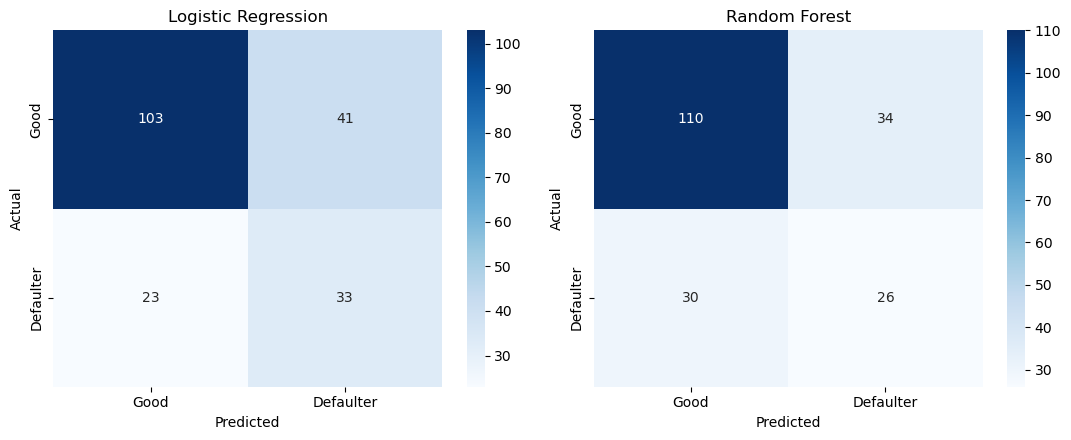

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, y_pred, title in zip(axes, [y_pred, y_pred_rf], ["Logistic Regression", "Random Forest"]):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["Good", "Defaulter"], yticklabels=["Good", "Defaulter"], ax=ax)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(title)

plt.tight_layout()
plt.show()

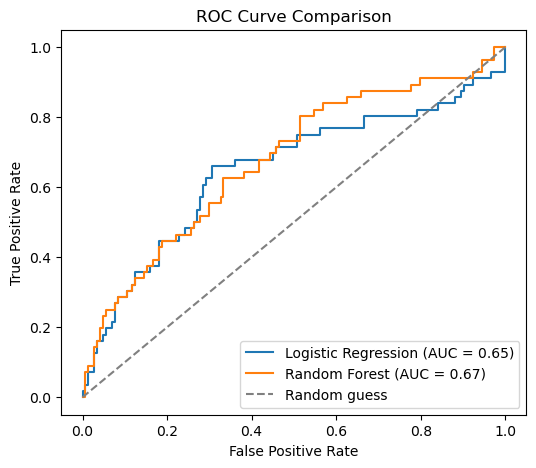

In [36]:
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_proba)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_proba_rf)
plt.figure(figsize=(6, 5))
plt.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC = {roc_auc_score(y_test, y_proba):.2f})")
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {roc_auc_score(y_test, y_proba_rf):.2f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

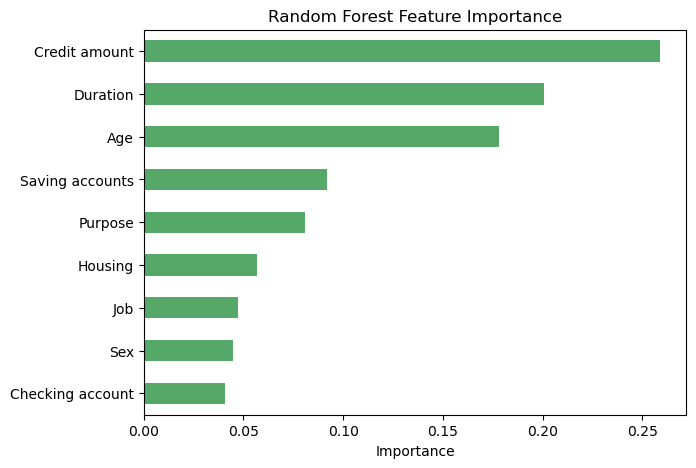

Credit amount       0.259043
Duration            0.200688
Age                 0.178130
Saving accounts     0.092048
Purpose             0.080814
Housing             0.056803
Job                 0.047035
Sex                 0.044553
Checking account    0.040886
dtype: float64

In [37]:
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(7, 5))
importances.plot(kind="barh", color="#55A868")
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.gca().invert_yaxis()
plt.show()
importances

9. Conclusion & Recommendation

Conclusion:
- Moderate cleaning of data was needed: Missing data for the attributes saving accounts / checking account were:
  Instead of random gaps, for meaningful gaps we encoded them as an explicit category.
  of dropping data.
- EDA demonstrated that the greater the length of the loan, the greater was the default risk, the larger the loan size, and the more an overdrawn checking account.
  accounting principles—all consistent with real-world accounting principles, and certain purposes (education, vacation/other).
  credit risk intuition.
- Both Logistic Regression and Random Forest were trained and evaluated using recall on the
  As the primary metrics, defaulter class and ROC-AUC with accuracy being misleading on this
  imbalanced target.
The most frequent answers were:Top three answers are: - Checking account status, Duration and Credit amount.
  Predictors are ubiquitous in both the correlation analysis and the "Random Forest feature importance.

Recommendation:
- Use Logistic Regression for production scoring model because of interpretability (each
  applicant's score confidential (keeping the score confidential for the loan officer and regulators), and is easily explained to the applicant in a readily understood manner.
  Random Forest as a ‘benchmark/challenger’ model to periodically sanity check the linear model's predictions.
  predictions.
- At the time of application, gather full information about Checking/Savings account, as
  it's the single strongest predictor and currently has the most missing data.
- diversify the types of loans that are eligible for approval, but for education and vacation-purpose loans, set a higher bar for approval, or
  These categories require some extra documentation, due to their higher default rates.
Prior to applying to production, test the model using a larger, more up-to-date dataset — this data is a
  Recall the well-known, but outdated set of benchmarks, and applicant behavior/economic conditions will have changed.
  It is since that time that it has been collected.